# Picking con deposito mobile: modello Gurobi

Implementazione didattica di [modello Gurobi](../src/gurobi_routing.py) con gli algoritmi Basic e ZoomIn. Eseguire le celle in ordine dalla radice del progetto dopo `uv sync`, usando il kernel della `.venv` e una licenza Gurobi 13 valida.

Il modello usa archi binari, un ingresso e un'uscita per ogni contenitore richiesto e tagli di capacità aggiunti nel callback `MIPSOL`. Le distanze dell'obiettivo Gurobi sono euclidee, senza arrotondamento. `OPTIMAL` certifica il routing a deposito fissato; Basic e ZoomIn cercano il deposito su griglie finite e ZoomIn rimane euristico.


In [1]:
import itertools
from math import dist
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import load_instance, solve_routes
from src.basic import basic_search
from src.comparison import compare
from src.visualization import plot_cost_map, plot_layout
from src.zoomin import zoomin_search

ROOT = (
    Path.cwd()
    if (Path.cwd() / "instances" / "PRP-UW-instances.txt").exists()
    else Path.cwd().parent
)
NAME = "44-(9x4)-10-01"
SOLVER = "gurobi"
LIMIT_SECONDS = 0.5  # per candidato; aumentare a 3 o 10 s per confronti più rigorosi
instance = load_instance(NAME, ROOT / "instances" / "PRP-UW-instances.txt")

## 1. Caricare l’ordine

`picklist` indica i prodotti richiesti; `assignment_for_random_storage_policy` associa ogni prodotto al contenitore fisico. Le quantità provengono da `weights`. La geometria segue la numerazione della figura 1 e le coppie sovrapposte condividono una coordinata.


In [2]:
print(
    f"{instance.name}: {instance.layout.count} contenitori, {len(instance.requested_locations)} prelievi, layout {instance.layout.n}×{instance.layout.m}"
)
print(
    f"Q={instance.capacity}, ν={instance.nu:.3f}, limiti deposito={instance.layout.bounds}"
)
picks_table = pd.DataFrame(
    [
        {
            "contenitore": k,
            "x_m": instance.layout.point(k)[0],
            "y_m": instance.layout.point(k)[1],
            "quantità": instance.qty_by_location[k],
        }
        for k in instance.requested_locations
    ]
)
display(picks_table)

44-(9x4)-10-01: 44 contenitori, 10 prelievi, layout 9×4
Q=15, ν=0.333, limiti deposito=(0.65, 10.8, -2.075, 2.075)


,contenitore,x_m,y_m,quantità
0,4,1.35,2.725,2
1,5,2.70,2.725,2
2,16,9.45,2.725,1
3,18,10.80,2.725,1
4,20,11.45,2.025,2
5,22,11.45,0.675,1
6,23,11.45,-0.675,1
7,33,6.75,-2.725,2
8,38,4.05,-2.725,4
9,39,2.70,-2.725,4


## 2. Disegnare il layout

I due numeri di ogni coppia indicano i livelli sovrapposti. Il punto O è l’ingresso; il deposito verde è scelto a mano.


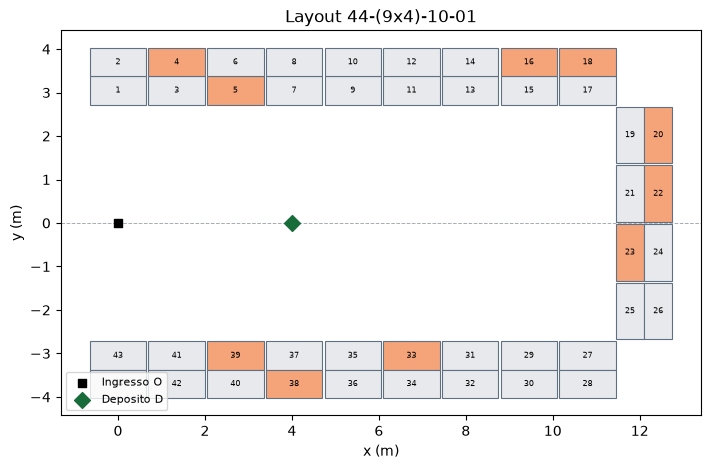

In [3]:
manual_depot = (4.0, 0.0)
plot_layout(instance, depot=manual_depot)
plt.show()

## 3. Risolvere i giri a deposito fisso

Il callback esamina ogni soluzione intera: per un giro con carico superiore a $Q$ o un ciclo isolato aggiunge il vincolo di uscita del gruppo tramite `cbLazy`. Il deposito può essere visitato da più giri. `OPTIMAL` prova l'ottimalità per il deposito fissato; `FEASIBLE` indica una soluzione senza prova nel tempo dato. Se non c'è una soluzione, distanza e costo sono `None`.


Set parameter Username


Set parameter LicenseID to value 2872861


Academic license - for non-commercial use only - expires 2027-10-08


Stato: OPTIMAL
Giro 1: D → 4 → 5 → 16 → 18 → 20 → 22 → 23 → 33 → D; carico=12/15; distanza=25.905 m
Giro 2: D → 38 → 39 → D; carico=8/15; distanza=7.095 m
Distanza picker totale: 33.00005686553789


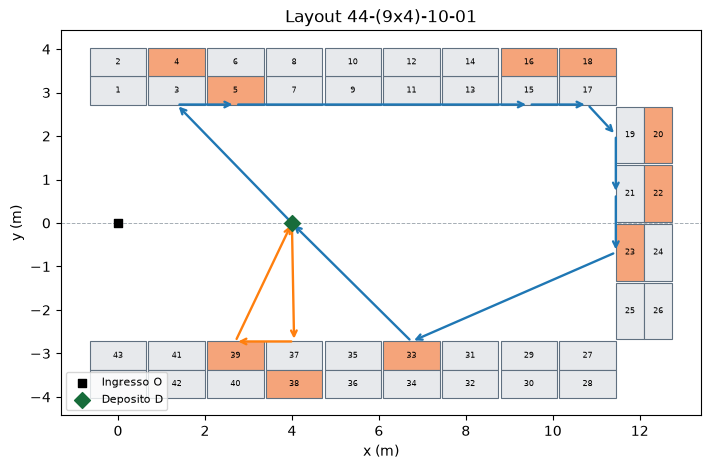

In [4]:
manual_route = solve_routes(instance, manual_depot, LIMIT_SECONDS, solver=SOLVER)
print("Stato:", manual_route.status)
for number, (tour, load) in enumerate(
    zip(manual_route.tours, manual_route.tour_loads), 1
):
    points = [manual_depot] + [instance.layout.point(k) for k in tour] + [manual_depot]
    hand_distance = sum(dist(a, b) for a, b in itertools.pairwise(points))
    print(
        f"Giro {number}: D → {' → '.join(map(str, tour))} → D; carico={load}/{instance.capacity}; distanza={hand_distance:.3f} m"
    )
print("Distanza picker totale:", manual_route.picker_distance)
plot_layout(instance, depot=manual_depot, route=manual_route)
plt.show()

## 4. Basic: scansione uniforme

La griglia è ancorata al limite inferiore di ogni asse. I punti senza soluzione entro il limite rimangono registrati con costo mancante.


Deposito manuale: (4.0, 0.0), costo=34.333
1D migliore: (3.65, 0.0) costo: 34.133 candidati: 11 ottimi: 11
2D migliore: (3.65, -2.075) costo: 31.387 candidati: 55 ottimi: 55


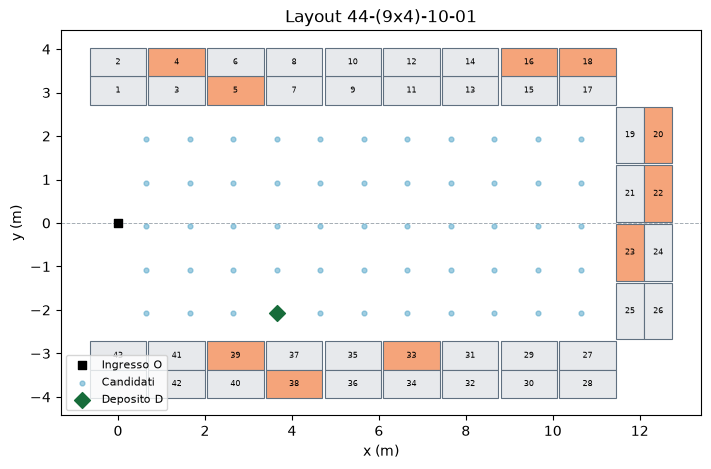

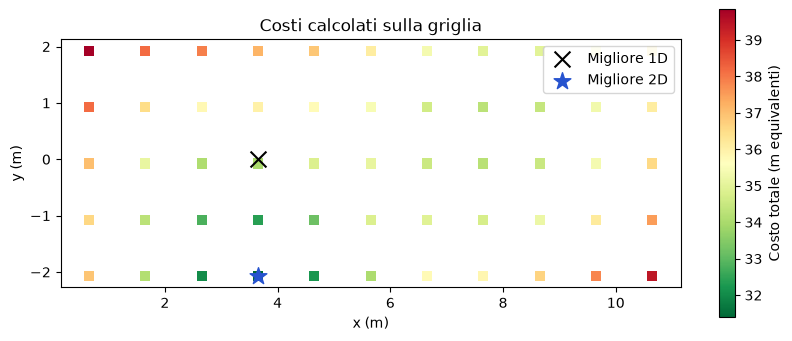

In [5]:
basic_1d = basic_search(
    instance, step=1.0, mode="1d", limit_seconds=LIMIT_SECONDS, solver=SOLVER
)
basic_2d = basic_search(
    instance, step=1.0, mode="2d", limit_seconds=LIMIT_SECONDS, solver=SOLVER
)
assert manual_route.picker_distance is not None
manual_total_cost = manual_route.picker_distance + instance.nu * dist(
    (0, 0), manual_depot
)
print(f"Deposito manuale: {manual_depot}, costo={manual_total_cost:.3f}")
for label, result in (("1D", basic_1d), ("2D", basic_2d)):
    print(
        label,
        "migliore:",
        result.best.depot if result.best else None,
        "costo:",
        round(result.best.total_cost, 3)
        if result.best and result.best.total_cost is not None
        else None,
        "candidati:",
        len(result.candidates),
        "ottimi:",
        result.optimal_count,
    )
plot_layout(
    instance,
    depot=basic_2d.best.depot if basic_2d.best else None,
    candidates=tuple(c.depot for c in basic_2d.candidates),
)
plt.show()
plot_cost_map(
    basic_2d,
    best_1d=basic_1d.best.depot if basic_1d.best else None,
    best_2d=basic_2d.best.depot if basic_2d.best else None,
)
plt.show()

## 5. ZoomIn: restringere la zona

Il primo passo copre tutta l’area. Ogni riquadro seguente è centrato sul migliore della scansione corrente; il migliore globale resta quello con il minor costo tra tutte le iterazioni.


1D arresto: minimum_step migliore: (3.05, 0.0)


,iterazione,passo_m,riquadro,candidati,fattibili,migliore,costo
0,1,2.0,"(0.65, 10.8, -2.075, 2.075)",6,6,"(2.65, 0.0)",34.197437
1,2,0.4,"(0.65, 4.65, -2.0, 2.0)",11,11,"(3.05, 0.0)",34.056583


2D arresto: minimum_step migliore: (3.45, -2.075)


,iterazione,passo_m,riquadro,candidati,fattibili,migliore,costo
0,1,2.0,"(0.65, 10.8, -2.075, 2.075)",18,18,"(2.65, -2.075)",32.024366
1,2,0.4,"(0.65, 4.65, -2.075, -0.075)",66,66,"(3.45, -2.075)",31.404590


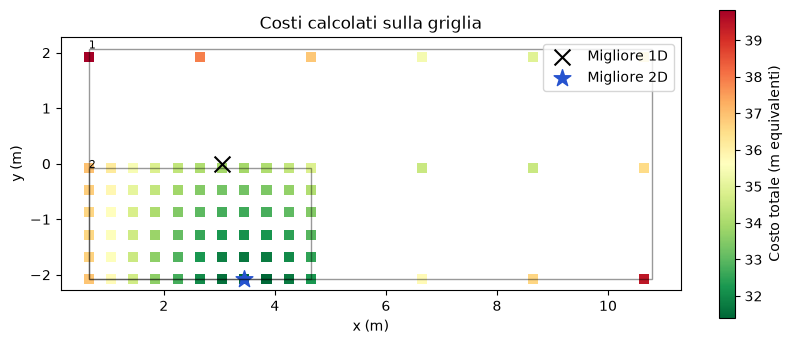

In [6]:
zoom_1d = zoomin_search(
    instance,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    mode="1d",
    limit_seconds=LIMIT_SECONDS,
    solver=SOLVER,
)
zoom_2d = zoomin_search(
    instance,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    mode="2d",
    limit_seconds=LIMIT_SECONDS,
    solver=SOLVER,
)
for label, result in (("1D", zoom_1d), ("2D", zoom_2d)):
    print(
        label,
        "arresto:",
        result.stop_reason,
        "migliore:",
        result.best.depot if result.best else None,
    )
    display(
        pd.DataFrame(
            [
                {
                    "iterazione": i,
                    "passo_m": scan.step,
                    "riquadro": scan.bounds,
                    "candidati": len(scan.candidates),
                    "fattibili": scan.feasible_count,
                    "migliore": scan.best.depot if scan.best else None,
                    "costo": scan.best.total_cost if scan.best else None,
                }
                for i, scan in enumerate(result.scans, 1)
            ]
        )
    )
plot_cost_map(
    zoom_2d,
    best_1d=zoom_1d.best.depot if zoom_1d.best else None,
    best_2d=zoom_2d.best.depot if zoom_2d.best else None,
)
plt.show()

## 6. Confrontare i quattro casi Gurobi

La tabella ricontrolla i carichi e la decomposizione del costo. Il tempo è per l'intera ricerca, mentre `limit_per_candidate_s` è il limite di ogni problema a deposito fissato. I costi dei candidati `FEASIBLE` possono migliorare con più tempo.


In [7]:
# Stessi parametri per entrambe le modalità; compare riesegue le quattro ricerche.
report = compare(
    instance,
    basic_step=1.0,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    limit_seconds=LIMIT_SECONDS,
    solver=SOLVER,
)
display(report.table.round(3))
print("Miglioramento 2D su 1D (%):", report.improvement_percent)
for method in ("Basic", "ZoomIn"):
    for mode in ("1d", "2d"):
        result = report.results[f"{method} {mode}"]
        if result.best and result.best.total_cost is not None:
            route = result.best.route
            assert route.picker_distance is not None
            expected_total_cost = route.picker_distance + instance.nu * dist(
                (0, 0), result.best.depot
            )
            assert abs(result.best.total_cost - expected_total_cost) < 1e-9

,depot,tours,picker_distance_m,weighted_forklift_distance_m,total_cost_m,candidates,feasible,optimal,elapsed_s,limit_per_candidate_s,basic_step_m,initial_step_m,minimum_step_m,reduction
method,,,,,,,,,,,,,,
Basic 1d,"(3.65, 0.0)",2,32.916,1.217,34.133,11,11,11,0.066,0.5,1.0,NaN,NaN,NaN
ZoomIn 1d,"(3.05, 0.0)",2,33.040,1.017,34.057,17,17,17,0.174,0.5,NaN,2.0,0.4,5.0
Basic 2d,"(3.65, -2.075)",2,29.987,1.400,31.387,55,55,55,0.333,0.5,1.0,NaN,NaN,NaN
ZoomIn 2d,"(3.45, -2.075)",2,30.063,1.342,31.405,84,84,84,1.410,0.5,NaN,2.0,0.4,5.0


Miglioramento 2D su 1D (%): {'Basic': 8.045609737443003, 'ZoomIn': 7.787021180416032}


## 7. Confronto con CP-SAT

Eseguiamo CP-SAT con gli stessi parametri di istanza, griglie iniziali e limite per candidato. Gurobi ottimizza le distanze reali; CP-SAT ottimizza coefficienti arrotondati a $10^{-4}$ m e poi ricalcola la distanza reale dei giri trovati. Per un candidato con stato `OPTIMAL` in entrambi i solver, una piccola differenza può quindi dipendere dall'arrotondamento. I risultati di ZoomIn possono usare griglie successive diverse se cambia il miglior candidato di una scansione. I tempi sono indicativi della singola esecuzione e non costituiscono un benchmark: risentono di cache, avvio e ordine delle chiamate.


In [8]:
cp_report = compare(
    instance,
    basic_step=1.0,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    limit_seconds=LIMIT_SECONDS,
    solver="cp_sat",
)
rows = []
for method in report.results:
    gurobi_result = report.results[method]
    cp_result = cp_report.results[method]
    gurobi_best = gurobi_result.best
    cp_best = cp_result.best
    gurobi_cost = gurobi_best.total_cost if gurobi_best else None
    cp_cost = cp_best.total_cost if cp_best else None
    gurobi_points = {candidate.depot for candidate in gurobi_result.candidates}
    cp_points = {candidate.depot for candidate in cp_result.candidates}
    rows.append(
        {
            "metodo": method,
            "deposito_gurobi": gurobi_best.depot if gurobi_best else None,
            "costo_gurobi_m": gurobi_cost,
            "stato_gurobi": gurobi_best.status if gurobi_best else None,
            "deposito_cp_sat": cp_best.depot if cp_best else None,
            "costo_cp_sat_m": cp_cost,
            "stato_cp_sat": cp_best.status if cp_best else None,
            "delta_gurobi_meno_cp_m": (
                gurobi_cost - cp_cost
                if gurobi_cost is not None and cp_cost is not None
                else None
            ),
            "stessi_candidati": gurobi_points == cp_points,
            "ottimi_gurobi": gurobi_result.optimal_count,
            "ottimi_cp_sat": cp_result.optimal_count,
            "tempo_gurobi_s": gurobi_result.elapsed_seconds,
            "tempo_cp_sat_s": cp_result.elapsed_seconds,
        }
    )
comparison_table = pd.DataFrame(rows).set_index("metodo")
display(comparison_table.round(4))

# Confronto diretto dei solver sullo stesso deposito scelto a mano.
cp_manual_route = solve_routes(instance, manual_depot, LIMIT_SECONDS, solver="cp_sat")
display(
    pd.DataFrame(
        [
            {
                "solver": name,
                "stato": route.status,
                "distanza_picker_m": route.picker_distance,
                "giri": len(route.tours) if route.feasible else None,
                "tempo_s": route.elapsed_seconds,
            }
            for name, route in (("Gurobi", manual_route), ("CP-SAT", cp_manual_route))
        ]
    )
    .set_index("solver")
    .round(4)
)

,deposito_gurobi,costo_gurobi_m,stato_gurobi,deposito_cp_sat,costo_cp_sat_m,stato_cp_sat,delta_gurobi_meno_cp_m,stessi_candidati,ottimi_gurobi,ottimi_cp_sat,tempo_gurobi_s,tempo_cp_sat_s
metodo,,,,,,,,,,,,
Basic 1d,"(3.65, 0.0)",34.1329,OPTIMAL,"(3.65, 0.0)",34.1329,OPTIMAL,0.0,True,11,10,0.0662,1.6507
ZoomIn 1d,"(3.05, 0.0)",34.0566,OPTIMAL,"(3.05, 0.0)",34.0566,OPTIMAL,0.0,True,17,15,0.1741,2.6538
Basic 2d,"(3.65, -2.075)",31.3867,OPTIMAL,"(3.65, -2.075)",31.3867,OPTIMAL,0.0,True,55,55,0.3333,2.8970
ZoomIn 2d,"(3.45, -2.075)",31.4046,OPTIMAL,"(3.45, -2.075)",31.4046,OPTIMAL,0.0,True,84,84,1.4099,4.5096


,stato,distanza_picker_m,giri,tempo_s
solver,,,,
Gurobi,OPTIMAL,33.0001,2,0.0035
CP-SAT,OPTIMAL,33.0001,2,0.0413


### Fonti

- [Modello Gurobi del progetto](../src/gurobi_routing.py).
- [Montemanni, Cervino e Lolli, *Picking Optimization in U-Shaped Corridors with a Movable Depot*](https://doi.org/10.1007/978-3-031-58113-7_12), figura 1 e tabelle 1–2.
- [Documentazione Gurobi: `cbLazy`](https://docs.gurobi.com/projects/optimizer/en/current/reference/python/model.html#Model.cbLazy).
